# Reverse engineering the spike recording
**Authors:** Omer Aharonovich, Axel Fridman, Mai Tucker

Estimation of the model behind `spike_data.npz`, a generator with the same structure, and checks that both agree.

Model: voltage = drift (one slow sine) + white gaussian noise + spikes. Each spike jumps to A in one sample and decays as exp(-t/tau). The spike times are a self-exciting poisson process with a refractory time: every spike makes more spikes likely for some ms after it (`excite = 0` gives independent poisson spikes).

In [1]:
import os
from dataclasses import asdict, dataclass, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import median_filter
from scipy.optimize import curve_fit, minimize
from scipy.stats import chi2

plt.rcParams.update({'figure.figsize': (11, 3.2), 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('figures', exist_ok=True)


def show(fig, name):
    fig.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


with np.load('spike_data.npz') as d:
    t, x = d['t'], d['raw_data']
print(len(x), 'samples,', round(1 / np.median(np.diff(t))), 'Hz,', round(len(x) * np.median(np.diff(t)), 3), 's')

10000 samples, 1000 Hz, 10.0 s


## 1. Coefficients
The defaults are the values estimated from `spike_data.npz` in section 4.

In [2]:
@dataclass
class Params:
    fs: float = 1000.0           # sample rate (Hz)
    offset: float = 0.0043       # drift = offset + drift_amp * sin(2 pi drift_freq t + drift_phase)
    drift_amp: float = 0.6468
    drift_freq: float = 0.09076  # Hz
    drift_phase: float = 0.2930  # rad
    noise_sd: float = 0.2985     # white gaussian noise
    rate: float = 4.2            # mean spikes per second
    refractory: float = 0.010    # s, shortest time between two spikes
    excite: float = 0.138        # extra spikes that one spike causes on average (0 = independent poisson)
    excite_tau: float = 0.0270   # s, how long this extra chance lasts after a spike
    spike_amp: float = 4.990     # jump of a spike
    spike_amp_sd: float = 0.077  # spike to spike spread of the jump
    spike_tau: float = 0.002944  # s, decay of a spike
    spike_tau_sd: float = 0.0    # spike to spike spread of tau
    kernel_len: float = 0.030    # s, length of one spike


pd.Series(asdict(Params()), name='default').to_frame()

,default
fs,1000.000000
offset,0.004300
drift_amp,0.646800
drift_freq,0.090760
drift_phase,0.293000
noise_sd,0.298500
rate,4.200000
refractory,0.010000
excite,0.138000
excite_tau,0.027000


## 2. Generator

In [3]:
def drift(t, p):
    return p.offset + p.drift_amp * np.sin(2 * np.pi * p.drift_freq * t + p.drift_phase)


def noise(n, p, rng):
    return rng.normal(0, p.noise_sd, n)


def spike_times(duration, p, rng):
    # background spikes are poisson; every spike gets on average `excite` extra spikes, exp(excite_tau) later.
    # the clock of the neuron stops during the refractory time, so the mean rate is exactly p.rate
    assert 0 <= p.excite < 1 and p.rate * p.refractory < 1, 'need excite < 1 and refractory < 1 / rate'
    mu = p.rate * (1 - p.excite) / (1 - p.rate * p.refractory)
    gen = rng.uniform(0, duration, rng.poisson(mu * duration))
    live = [gen]
    while len(gen):
        kids = np.repeat(gen, rng.poisson(p.excite, len(gen)))
        gen = kids + rng.exponential(p.excite_tau, len(kids))
        gen = gen[gen < duration]
        live.append(gen)
    live = np.sort(np.concatenate(live))
    times = live + p.refractory * np.arange(len(live))
    return (times[times < duration] * p.fs).astype(int)


def spike_train(idx, n, p, rng):
    k = np.arange(int(p.kernel_len * p.fs)) / p.fs
    amps = p.spike_amp + p.spike_amp_sd * rng.standard_normal(len(idx))
    taus = np.maximum(p.spike_tau + p.spike_tau_sd * rng.standard_normal(len(idx)), 1e-4)
    s = np.zeros(n)
    for i, a, tau in zip(idx, amps, taus):
        m = min(len(k), n - i)
        s[i:i + m] += a * np.exp(-k[:m] / tau)
    return s


def simulate(duration=10.0, rate=None, seed=None, p=None, **changes):
    # returns t, x and the true spike indices
    p = replace(p or Params(), **changes)
    if rate is not None:
        p = replace(p, rate=rate)
    rng = np.random.default_rng(seed)
    n = int(round(duration * p.fs))
    t = np.arange(n) / p.fs
    idx = spike_times(duration, p, rng)
    return t, drift(t, p) + noise(n, p, rng) + spike_train(idx, n, p, rng), idx

## 3. Estimation
Spike detector of HW2 (0.5 s rolling median, threshold 5 robust SD, min. 2 samples, merge peaks < 8 ms), least squares for the spike shape and the drift sine, maximum likelihood for the spike times.

In [4]:
def detect_spikes(x, k=5, win=501, min_len=2, dead=8):
    r = x - median_filter(x, size=win, mode='reflect')
    sigma = np.median(np.abs(r - np.median(r))) / 0.6745
    above = np.concatenate(([False], r > k * sigma, [False]))
    starts, ends = np.flatnonzero(above[1:] & ~above[:-1]), np.flatnonzero(above[:-1] & ~above[1:])
    spikes = []
    for s, e in zip(starts, ends):
        if e - s < min_len:
            continue
        p = s + np.argmax(r[s:e])
        if spikes and p - spikes[-1] < dead:
            if r[p] > r[spikes[-1]]:
                spikes[-1] = p
        else:
            spikes.append(p)
    return np.array(spikes, dtype=int), r


def hawkes_fit(idx, fs, duration, d):
    # returns excite, excite_tau and the likelihood ratio against independent poisson spikes
    t = idx / fs
    s = t - d * np.arange(len(t))
    S = duration - np.minimum(d, duration - t).sum()

    def nll(q):
        mu, alpha, beta = np.exp(q[0]), 1 / (1 + np.exp(-np.clip(q[1], -20, 8))), np.exp(np.clip(q[2], -2, 9))
        E, e = np.zeros(len(s)), 0.0
        for i, a in enumerate(np.exp(-beta * np.diff(s)), 1):
            e = a * (1 + e)
            E[i] = e
        return mu * S + alpha * (1 - np.exp(-beta * np.clip(S - s, 0, None))).sum() - np.log(mu + alpha * beta * E).sum()

    fits = [minimize(nll, [np.log(len(s) / S), a0, np.log(b0)], method='Nelder-Mead', options={'maxiter': 3000})
            for a0 in (-2, 0) for b0 in (10, 50)]
    best = min(fits, key=lambda r: r.fun)
    nll_poisson = len(s) - len(s) * np.log(len(s) / S)
    return (1 / (1 + np.exp(-np.clip(best.x[1], -20, 8))), 1 / np.exp(np.clip(best.x[2], -2, 9)),
            2 * (nll_poisson - best.fun))


def estimate(t, x, kernel_len=25):
    fs = 1 / np.median(np.diff(t))
    idx, r = detect_spikes(x)
    k = np.arange(kernel_len)
    iso = [i for i in idx if np.all(np.abs(idx[idx != i] - i) > kernel_len) and i + kernel_len <= len(x)]
    (a, tau), _ = curve_fit(lambda k, a, tau: a * np.exp(-k / tau), np.tile(k, len(iso)),
                            np.concatenate([r[i:i + kernel_len] for i in iso]), p0=(5, 3))
    p = Params(fs=fs, spike_amp=a, spike_amp_sd=0, spike_tau=tau / fs,
               refractory=min(0.010, np.diff(idx).min() / fs))
    y = x - spike_train(idx, len(x), p, np.random.default_rng(0))
    freqs = np.fft.rfftfreq(len(y), 1 / fs)
    f0 = freqs[1 + np.argmax(np.abs(np.fft.rfft(y - y.mean()))[1:])]
    sine = lambda t, c, s, co, f: c + s * np.sin(2 * np.pi * f * t) + co * np.cos(2 * np.pi * f * t)
    (c, s, co, f), _ = curve_fit(sine, t, y, p0=(y.mean(), y.std(), 0, f0))
    if f < 0:
        f, s = -f, -s
    noise_sd = np.std(y - sine(t, c, s, co, f))
    h = np.exp(-k / tau)
    amps = np.array([r[i:i + kernel_len] @ h / (h @ h) for i in iso])
    amp_sd = np.sqrt(max(amps.var(ddof=1) - noise_sd ** 2 / (h @ h), 0))  # spread minus the part of the noise
    excite, excite_tau, _ = hawkes_fit(idx, fs, len(x) / fs, p.refractory)
    return replace(p, offset=c, drift_amp=np.hypot(s, co), drift_freq=f, drift_phase=np.arctan2(co, s),
                   noise_sd=noise_sd, rate=len(idx) / (len(x) / fs), spike_amp_sd=amp_sd,
                   excite=excite, excite_tau=excite_tau)

## 4. Estimation on the real recording

In [5]:
p = estimate(t, x)
idx_real, r_real = detect_spikes(x)
pd.Series(asdict(p), name='estimated from spike_data.npz').to_frame()

,estimated from spike_data.npz
fs,1000.000000
offset,0.004268
drift_amp,0.646782
drift_freq,0.090760
drift_phase,0.292981
noise_sd,0.298477
rate,4.200000
refractory,0.010000
excite,0.138415
excite_tau,0.027021


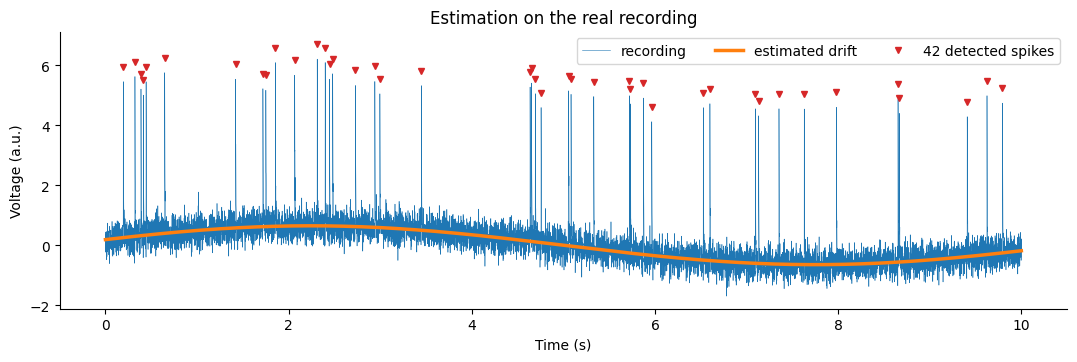

In [6]:
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(t, x, lw=0.4, label='recording')
ax.plot(t, drift(t, p), lw=2.5, color='C1', label='estimated drift')
ax.plot(t[idx_real], x[idx_real] + 0.5, 'v', color='C3', ms=5, label=f'{len(idx_real)} detected spikes')
ax.set(xlabel='Time (s)', ylabel='Voltage (a.u.)', title='Estimation on the real recording')
ax.legend(ncol=3, loc='upper right')
show(fig, 'estimation_real')

## 5. Real data vs simulation
Same detector for both. Change `DURATION`, `RATE`, `SEED` or any coefficient, for example `simulate(60, rate=10, excite=0)`.

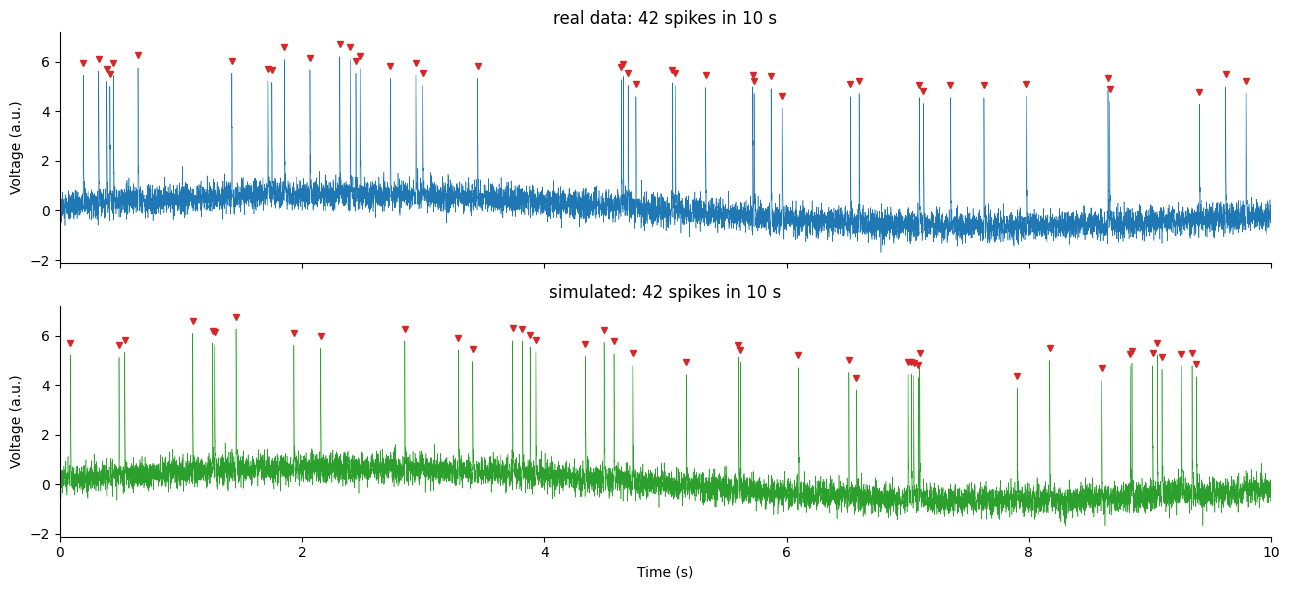

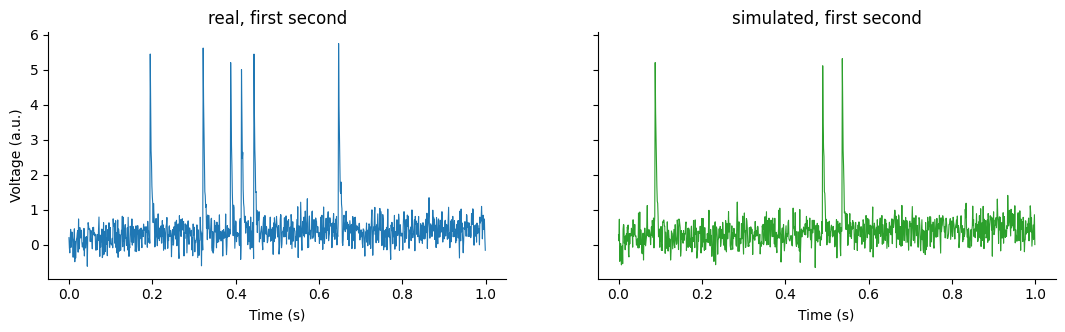

In [7]:
DURATION, RATE, SEED = 10, p.rate, 6
ts, xs, idx_true = simulate(DURATION, rate=RATE, seed=SEED, p=p)
idx_found = detect_spikes(xs)[0]

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)
axes[0].plot(t, x, lw=0.4, color='C0')
axes[0].plot(t[idx_real], x[idx_real] + 0.5, 'v', color='C3', ms=4)
axes[0].set(ylabel='Voltage (a.u.)', title=f'real data: {len(idx_real)} spikes in 10 s')
axes[1].plot(ts, xs, lw=0.4, color='C2')
axes[1].plot(ts[idx_found], xs[idx_found] + 0.5, 'v', color='C3', ms=4)
axes[1].set(xlabel='Time (s)', ylabel='Voltage (a.u.)', xlim=(0, DURATION),
            title=f'simulated: {len(idx_found)} spikes in {DURATION} s')
plt.tight_layout()
show(fig, 'real_vs_simulated')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for ax, (tt, xx, name, c) in zip(axes, [(t, x, 'real', 'C0'), (ts, xs, 'simulated', 'C2')]):
    m = tt < 1
    ax.plot(tt[m], xx[m], lw=0.8, color=c)
    ax.set(xlabel='Time (s)', title=f'{name}, first second')
axes[0].set(ylabel='Voltage (a.u.)')
show(fig, 'first_second')

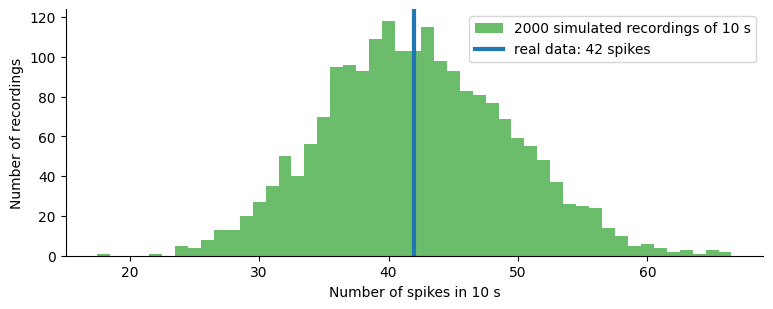

real data: 42 spikes | simulated: mean 42.2, 90% of the recordings between 31 and 54


In [8]:
counts = np.array([len(spike_times(10, p, np.random.default_rng(1000 + i))) for i in range(2000)])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(counts, bins=np.arange(counts.min(), counts.max() + 2) - 0.5, color='C2', alpha=0.7,
        label='2000 simulated recordings of 10 s')
ax.axvline(len(idx_real), color='C0', lw=3, label=f'real data: {len(idx_real)} spikes')
ax.set(xlabel='Number of spikes in 10 s', ylabel='Number of recordings')
ax.legend()
show(fig, 'spike_counts')
print(f'real data: {len(idx_real)} spikes | simulated: mean {counts.mean():.1f}, '
      f'90% of the recordings between {np.percentile(counts, 5):.0f} and {np.percentile(counts, 95):.0f}')

## 6. Does the estimation find the coefficients back?
10 min simulated with the coefficients of section 4, then estimated with the same code.

In [9]:
tl, xl, idx_long = simulate(600, seed=2, p=p)
q = estimate(tl, xl)
check = pd.DataFrame({'used in simulation': asdict(p), 'estimated back (10 min)': asdict(q)})
check['difference'] = check.iloc[:, 1] - check.iloc[:, 0]
print(len(idx_long), 'true spikes, detector finds', len(detect_spikes(xl)[0]))
check.round(5)

2520 true spikes, detector finds 2520


,used in simulation,estimated back (10 min),difference
fs,1000.00000,1000.00000,-0.00000
offset,0.00427,0.00630,0.00204
drift_amp,0.64678,0.64577,-0.00101
drift_freq,0.09076,0.09076,-0.00000
drift_phase,0.29298,0.29424,0.00126
noise_sd,0.29848,0.29862,0.00014
rate,4.20000,4.20000,-0.00000
refractory,0.01000,0.01000,0.00000
excite,0.13842,0.15687,0.01846
excite_tau,0.02702,0.02787,0.00085


## 7. Spike shape, noise and spike timing

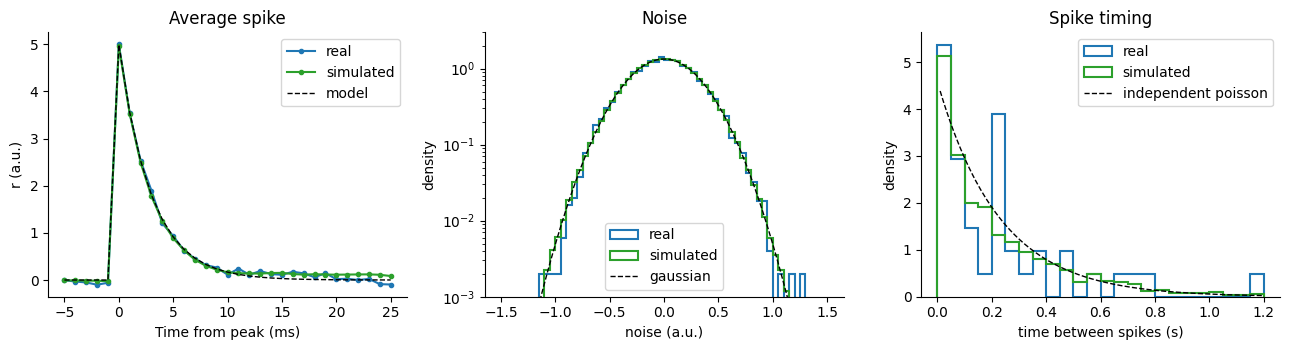

In [10]:
idx_sim, r_sim = detect_spikes(xl)
lag = np.arange(-5, 26)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

for idx, r, name, c in [(idx_real, r_real, 'real', 'C0'), (idx_sim, r_sim, 'simulated', 'C2')]:
    ok = idx[(idx > 5) & (idx < len(r) - 26)]
    axes[0].plot(lag, np.mean([r[i + lag] for i in ok], axis=0), 'o-', ms=3, color=c, label=name)
axes[0].plot(lag, np.where(lag >= 0, p.spike_amp * np.exp(-np.clip(lag, 0, None) / (p.spike_tau * p.fs)), 0),
             'k--', lw=1, label='model')
axes[0].set(xlabel='Time from peak (ms)', ylabel='r (a.u.)', title='Average spike')
axes[0].legend()

bins = np.linspace(-1.5, 1.5, 61)
clean = replace(p, spike_amp_sd=0)
for tt, xx, idx, name, c in [(t, x, idx_real, 'real', 'C0'), (tl, xl, idx_sim, 'simulated', 'C2')]:
    e = xx - drift(tt, p) - spike_train(idx, len(xx), clean, np.random.default_rng(0))
    axes[1].hist(e, bins=bins, density=True, histtype='step', lw=1.5, color=c, label=name)
v = np.linspace(-1.5, 1.5, 200)
axes[1].plot(v, np.exp(-v ** 2 / (2 * p.noise_sd ** 2)) / (p.noise_sd * np.sqrt(2 * np.pi)), 'k--', lw=1,
             label='gaussian')
axes[1].set(yscale='log', ylim=(1e-3, 3), xlabel='noise (a.u.)', ylabel='density', title='Noise')
axes[1].legend()

isi_bins = np.linspace(0, 1.2, 25)
for idx, name, c in [(idx_real, 'real', 'C0'), (idx_sim, 'simulated', 'C2')]:
    axes[2].hist(np.diff(idx) / p.fs, bins=isi_bins, density=True, histtype='step', lw=1.5, color=c, label=name)
lam = 1 / (1 / p.rate - p.refractory)
s = np.linspace(p.refractory, 1.2, 200)
axes[2].plot(s, lam * np.exp(-lam * (s - p.refractory)), 'k--', lw=1, label='independent poisson')
axes[2].set(xlabel='time between spikes (s)', ylabel='density', title='Spike timing')
axes[2].legend()
plt.tight_layout()
show(fig, 'shape_noise_timing')

## 8. Firing that is not independent

real data: excite 0.138, excite_tau 27.0 ms, likelihood ratio vs independent poisson 2.66 (p = 0.051)


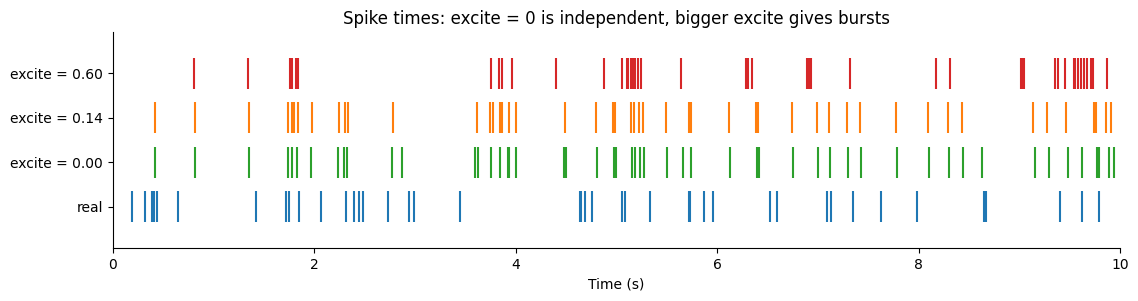

   real data: rate 4.20 Hz, fano factor (1 s) 1.26, isi cv 1.07
 excite 0.00: rate 4.28 Hz, fano factor (1 s) 0.87, isi cv 0.93
 excite 0.14: rate 4.28 Hz, fano factor (1 s) 1.10, isi cv 1.04
 excite 0.60: rate 4.25 Hz, fano factor (1 s) 5.67, isi cv 1.84


In [11]:
a, tau, LR = hawkes_fit(idx_real, p.fs, len(x) / p.fs, p.refractory)
print(f'real data: excite {a:.3f}, excite_tau {tau * 1000:.1f} ms, '
      f'likelihood ratio vs independent poisson {LR:.2f} (p = {0.5 * chi2.sf(LR, 1):.3f})')

rows = [('real', idx_real / p.fs)]
for a in [0.0, p.excite, 0.6]:
    rows.append((f'excite = {a:.2f}', spike_times(10, replace(p, excite=a), np.random.default_rng(4)) / p.fs))
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.eventplot([r for _, r in rows], colors=['C0', 'C2', 'C1', 'C3'], linelengths=0.7)
ax.set(yticks=range(len(rows)), yticklabels=[name for name, _ in rows], xlabel='Time (s)', xlim=(0, 10),
       title='Spike times: excite = 0 is independent, bigger excite gives bursts')
show(fig, 'spike_times')

cases = [('real data', idx_real, 10)]
for a in [0.0, p.excite, 0.6]:
    cases.append((f'excite {a:.2f}', spike_times(600, replace(p, excite=a), np.random.default_rng(5)), 600))
for name, idx, dur in cases:
    c = np.bincount(idx // int(p.fs), minlength=dur)
    isi = np.diff(idx)
    print(f'{name:>12}: rate {len(idx) / dur:.2f} Hz, fano factor (1 s) {c.var(ddof=1) / c.mean():.2f}, '
          f'isi cv {isi.std() / isi.mean():.2f}')

## 9. Other coefficients
Example: rate 15 Hz instead of the 4.2 Hz of the real data.

true rate 13.733 Hz, estimated rate 13.733 Hz


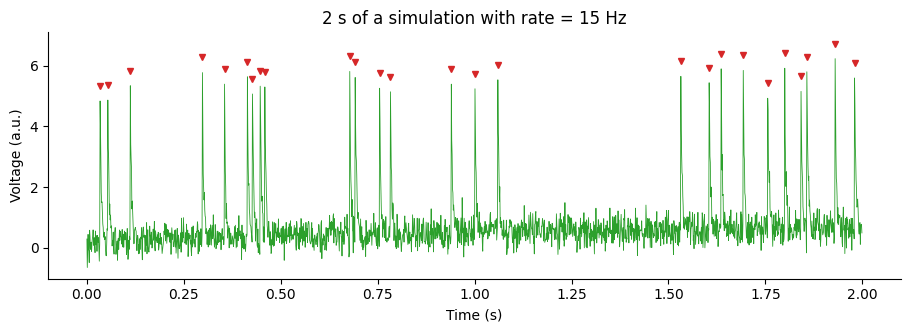

In [12]:
t15, x15, idx15 = simulate(30, rate=15, seed=3, p=p)
print('true rate', round(len(idx15) / 30, 3), 'Hz, estimated rate', round(estimate(t15, x15).rate, 3), 'Hz')
m = t15 < 2
fig, ax = plt.subplots()
ax.plot(t15[m], x15[m], lw=0.6, color='C2')
ax.plot(t15[idx15[idx15 < 2000]], x15[idx15[idx15 < 2000]] + 0.5, 'v', color='C3', ms=5)
ax.set(xlabel='Time (s)', ylabel='Voltage (a.u.)', title='2 s of a simulation with rate = 15 Hz')
show(fig, 'rate_15hz')

## 10. Generated data file
`simulated_spike_data.npz` is the simulation of section 5, in the same format as `spike_data.npz`. `simulated_true_spikes.csv` has its true spikes.

In [13]:
np.savez('simulated_spike_data.npz', t=ts, raw_data=xs)
pd.DataFrame({'sample': idx_true, 'time_s': ts[idx_true].round(3)}).to_csv('simulated_true_spikes.csv', index=False)
for name in ['spike_data.npz', 'simulated_spike_data.npz']:
    with np.load(name) as d:
        print(f'{name:>24}:', ', '.join(f'{k} {d[k].shape} {d[k].dtype}' for k in d.files))

          spike_data.npz: t (10000,) float64, raw_data (10000,) float64
simulated_spike_data.npz: t (10000,) float64, raw_data (10000,) float64


In [14]:
with np.load('simulated_spike_data.npz') as d:
    q10 = estimate(d['t'], d['raw_data'])
names = {'offset': 'drift offset', 'drift_amp': 'drift amplitude', 'drift_freq': 'drift frequency (Hz)',
         'drift_phase': 'drift phase (rad)', 'noise_sd': 'noise sd', 'rate': 'spike rate (Hz)',
         'spike_amp': 'spike amplitude', 'spike_amp_sd': 'spike amplitude spread', 'spike_tau': 'spike decay (ms)',
         'excite': 'excite (extra spikes per spike)', 'excite_tau': 'excite_tau (ms)'}
cols = {'real data (10 s)': p, 'simulated file (10 s)': q10, 'simulated (10 min)': q}
coef = pd.DataFrame({c: {names[k]: v * (1000 if k in ('spike_tau', 'excite_tau') else 1)
                         for k, v in asdict(e).items() if k in names} for c, e in cols.items()})
coef.round(4).to_csv('coefficients.csv')
coef.round(4)

,real data (10 s),simulated file (10 s),simulated (10 min)
drift offset,0.0043,0.0065,0.0063
drift amplitude,0.6468,0.6552,0.6458
drift frequency (Hz),0.0908,0.0909,0.0908
drift phase (rad),0.2930,0.2860,0.2942
noise sd,0.2985,0.3010,0.2986
spike rate (Hz),4.2000,4.2000,4.2000
excite (extra spikes per spike),0.1384,0.1473,0.1569
excite_tau (ms),27.0213,24.1281,27.8717
spike amplitude,4.9904,4.9870,4.9681
spike amplitude spread,0.0770,0.1930,0.0932
